### Solving 2D river stage boundary problem using HT-NN
* Development of a 2D HT-NN Framework
* HT-NN Model Training
* Model Performance Evaluation
* Synthetic Case Study

In [324]:
import os
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch.nn.functional as F
import torch.optim as optim
from trainer import *
from sle import *
from sklearn.metrics import r2_score
from torchmetrics.regression import R2Score
from torch.utils.data import ConcatDataset
from torch.utils.data import DataLoader, Dataset, random_split
from torch.optim.lr_scheduler import ReduceLROnPlateau, StepLR, MultiStepLR, CosineAnnealingLR

work_dir = work_dir = Path(os.getcwd())
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'torch is is_available on "{device}"')

def model_eval(model, input):
    
    # model input 
    if type(input) == np.ndarray:
        input = torch.from_numpy(input).float().to(device)
    
    # prediction
    with torch.no_grad():
        output = model(input)
    
    prediction = output.squeeze(0).cpu().detach().numpy() # remove batch dimension     
    
    return prediction

torch is is_available on "cuda"


### HT-NN framework

In [32]:
# Conv2d/Pooling calculator for rectangular
intput_size = (24, 24)
kernel_size = (2, 2)
stride = (2, 1)
padding = (0, 0)
H = 1 + (intput_size[0] + 2*padding[0]-(kernel_size[0]-1)-1)/stride[0]
W = 1 + (intput_size[1] + 2*padding[1]-(kernel_size[1]-1)-1)/stride[1]

print(f'output size H:{int(H)},  W:{int(W)}')

output size H:12,  W:23


In [29]:
# Convt2d calculator for rectangular
input_size = (15, 12)
kernel_size = (4, 4)
stride = (2, 2)
padding = (1, 1)
output_padding = (0, 0)  # optional

H = (input_size[0] - 1) * stride[0] - 2 * padding[0] + kernel_size[0] + output_padding[0]
W = (input_size[1] - 1) * stride[1] - 2 * padding[1] + kernel_size[1] + output_padding[1]

print(f'output size H:{int(H)},  W:{int(W)}')

output size H:30,  W:24


In [ ]:
# HTNN framework
class HTNN_Net(nn.Module):
    """
    Atttributes
    -----------
        in_channels = 1 -> Only inverse K
        init_features = 36 -> first conv output features
        out_channels = 18 -> 18 layers
        growth_rate  = 16 -> addtional features added in each densely connection
        layer_num = [3,3,...] -> number of layers in each dense block
        drop_rate = 0. -> dropout rate in each layer
    
    Input:
    -------
        x: tensor: (batch_size, 1, 50, 25)
    Output:
    -----------
        y: tensor: (batch_size, 1, 60, 50) # z, y, x
    """
    def __init__(self, 
                 in_channels,
                 init_features,
                 out_channels,
                 growth_rate,
                 layer_num,
                 drop_rate = 0.):
        super(HTNN_Net, self).__init__()

        self.out_channels = out_channels
        self.in_channels = in_channels
        self.init_features = init_features

        # (50, 25)
        self.in_conv = nn.Conv2d(in_channels, init_features, kernel_size=3, stride=1, padding=1, bias=False)
        num_features = init_features

        # (50, 25) => (24, 24)
        self.DTE1 = Dense_Transition_Encoder_block(init_features, growth_rate, layer_num[0], ((3, 2), (2, 1), (1, 0)), drop_rate=drop_rate)
        num_features = (num_features + layer_num[0] * growth_rate) // 2

        # (24, 24) => (12, 12)
        self.DTE2 = Dense_Transition_Encoder_block(num_features, growth_rate, layer_num[1], (4, 2, 1), drop_rate=drop_rate)
        num_features = (num_features + layer_num[1] * growth_rate) // 2

        # (12, 12) => (6, 6)
        self.DTE3 = Dense_Transition_Encoder_block(num_features, growth_rate, layer_num[2], (2, 2, 0), drop_rate=drop_rate)
        num_features = (num_features + layer_num[2] * growth_rate) // 2

        # (6, 6) => (3, 3)
        self.DTE4 = Dense_Transition_Encoder_block(num_features, growth_rate, layer_num[3], (2, 2, 0), drop_rate=drop_rate)
        num_features = (num_features + layer_num[2] * growth_rate) // 2

# switch to decoder

        # (3, 3) => (6, 6)
        self.DTD1 = Dense_Transition_Decoder_block(num_features, growth_rate, layer_num[4], (2, 2, 0), drop_rate=drop_rate)
        num_features = (num_features + layer_num[4] * growth_rate) // 2

        # (6, 6) => (15, 12)
        self.DTD2 = Dense_Transition_Decoder_block(num_features, growth_rate, layer_num[5], ((5, 2), (2, 2), (0, 0)), drop_rate=drop_rate)
        num_features = (num_features + layer_num[5] * growth_rate) // 2

        # (15, 12) => (30, 25)
        self.DTD3 = Dense_Transition_Decoder_block(num_features, growth_rate, layer_num[6], ((4, 5), (2, 2), (1, 1)), drop_rate=drop_rate)
        num_features = (num_features + layer_num[6] * growth_rate) // 2

        # (30, 25) => (60, 50)
        self.DTD4 = Dense_Transition_Decoder_block(num_features, growth_rate, layer_num[7], (4, 2, 1), drop_rate=drop_rate)
        num_features = (num_features + layer_num[7] * growth_rate) // 2

        self.out_conv = nn.Conv2d(num_features, self.out_channels, kernel_size=3, stride=1, padding=1, bias=False)        
        self.out_activation = Activation_block(negative_slope=0.5)

    def forward(self, x):

        x = self.in_conv(x)
        # print(f'after "channel_expand_conv2d": {x.shape}')
        x = self.DTE1(x)
        # print(f'after "DTE1": {x.shape}')
        x = self.DTE2(x)
        # print(f'after "DTE2": {x.shape}')
        x = self.DTE3(x)
        # print(f'after "DTE3": {x.shape}')
        x = self.DTE4(x)
        # print(f'after "DTE4": {x.shape}')

        x = self.DTD1(x)
        # print(f'after "DTD1": {x.shape}')
        x = self.DTD2(x)
        # print(f'after "DTD2": {x.shape}')
        x = self.DTD3(x)
        # print(f'after "DTD3": {x.shape}')
        x = self.DTD4(x)
        # print(f'after "DTD4": {x.shape}')      
        x = self.out_activation(x)
        y = self.out_conv(x)

        return y     

In [ ]:
# check model dimension

model_test = HTNN_Net(
            in_channels=1,     # Adjust based on your input channels
            init_features=54,
            out_channels=1,
            growth_rate=12,
            layer_num= [2]*8, # Adjust based on your architecture [3, 3, 6, 8, 6, 3, 3]
            # base_channels= 64,
            drop_rate=0.)

dummy_input = torch.randn(1, 1, 50, 25) # Random test data

# Run through the model
output = model_test(dummy_input)
print(output.shape)

torch.Size([1, 1, 60, 50])


### Model training

Contain total "2484" training set
model input: torch.Size([1, 50, 25]), output torch.Size([1, 60, 50])


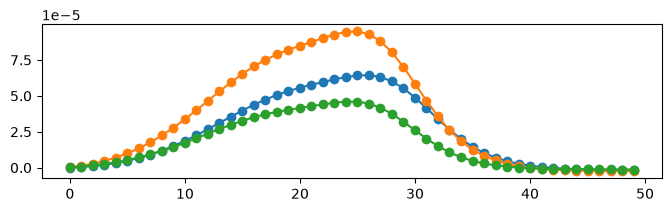

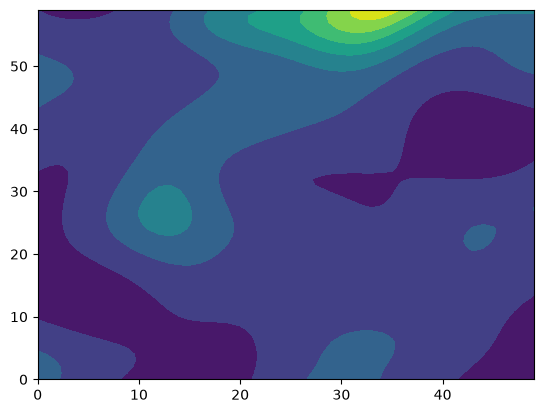

In [329]:
# check input/output
training_data_dir = Path.cwd() / 'toy_case' /'training_data'
dataset = NNDataset(training_data_dir, 'toy_case_2D')
print(f'Contain total "{len(dataset)}" training set')

idx = np.random.randint(len(dataset))
input_head, output_para =  dataset[idx]
print(f'model input: {input_head.shape}, output {output_para.shape}')

plt.figure(figsize = (8, 2))
plt.plot(input_head.squeeze(0)[:, 1], '-o')
plt.plot(input_head.squeeze(0)[:, 5], '-o')
plt.plot(input_head.squeeze(0)[:, 2], '-o')
plt.show()

plt.contourf(output_para.squeeze(0))
plt.show()

In [ ]:
# Set parameters
args = ({
        
    # for saving
    'project_name': 'toy_case_2D',
    'save_dir': Path.cwd()/'training_result',
    'saving_name':'test_1114', 
    
    # for instantiating train model
    'in_channels': 1,                 # number of head channel
    'out_channels':1,                 # Nz number
    'init_features':12,                # feature maps number after the 1st convolution
    'layer_num': [8]*8,               # contain 5 Encoder block (EB), 4 Decoder block (DB); test from 3, 5, 7, 9, 11, 12
    'drop_rate': 0.1, 

    # for training data
    'training_folder': ['toy_case_2D', 'toy_case_2D_2'], 
    'train_portion': 0.7,
    'valid_portion': 0.15,
    'test_portion' : 0.15,           # approx equal total dataset* [ 1 - (train_protion + valid_portion) ]
    'data_spliting_seed': 20261114,

    # for training process
    'criterion': 'L1', # MAE
    'optimizer': 'Adam',
    'scheduler': 'CosineAnnealingLR',
    'n_epochs': 100,
    'lr': 0.001,
    'growth_rate': 16,               # test from 16, 20, 24, 28
    'batch_size': 16,                # test from 32, 64, 128, 256, 512
    'weight_decay':  0, # 5e-5
    'l1_weight': 0.0,
})

for item, value in args.items():
    print(f'{item}: {value}')

project_name: toy_case_2D
save_dir: c:\Users\Ethan\Desktop\ethan\專案\HTNN-2D\training_result
saving_name: test_1114
in_channels: 1
out_channels: 1
init_features: 1
layer_num: [8, 8, 8, 8, 8, 8, 8, 8]
drop_rate: 0.1
training_folder: ['toy_case_2D', 'toy_case_2D_2']
train_portion: 0.7
valid_portion: 0.15
test_portion: 0.15
data_spliting_seed: 20261114
criterion: L1
optimizer: Adam
scheduler: CosineAnnealingLR
n_epochs: 100
lr: 0.001
growth_rate: 16
batch_size: 16
weight_decay: 0
l1_weight: 0.0


In [ ]:
# load dataset    
print(f'The training using {args["training_folder"]} for training')
# training_data_dir = Path.cwd()/'training_data'

sub_list = []
for material_folder in args['training_folder']:
    print(f' -- process material folder {material_folder} --')
    subdata = NNDataset(training_data_dir, material_folder)
    sub_list.append(subdata)
dataset = ConcatDataset(sub_list)
# dataset = NNDataset(training_data_dir, 'toy_case_2D')

generator = torch.Generator().manual_seed(args['data_spliting_seed'])
total_length = len(dataset)
train_length = int(total_length * args['train_portion'])
valid_length = int(total_length * args['valid_portion'])
test_length = total_length - train_length - valid_length
train_data, valid_data, test_data = random_split(
    dataset, [train_length, valid_length, test_length], generator=generator
)

# -- DataLoader --
train_dataloader = DataLoader(dataset=train_data, batch_size=args['batch_size'], shuffle=True, drop_last=True)
valid_dataloader = DataLoader(dataset=valid_data, batch_size=args['batch_size'], shuffle=False, drop_last=False)
test_dataloader  = DataLoader(dataset=test_data,  batch_size=args['batch_size'], shuffle=False, drop_last=False)
print(f"Training data: {train_length} | Validation data: {valid_length} | Testing data: {test_length}")

# -- Instantiate the model --
model = HTNN_Net(
            in_channels   = args['in_channels'],     # Adjust based on your input channels
            init_features = args['init_features'],
            out_channels  = args['out_channels'],
            growth_rate   = args['growth_rate'],
            layer_num     = args['layer_num'],       # Adjust based on your architecture
            drop_rate     = args['drop_rate']
            )
model = model.to(device)

# -- Loss and optimizer --
# criterion = nn.L1Loss()
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=args['lr'], weight_decay = args['weight_decay'])
# scheduler = ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=3, threshold = 0.0001, verbose=True)
# scheduler = StepLR(optimizer,step_size= 10, gamma = 0.1)
scheduler = CosineAnnealingLR(optimizer, T_max= args['n_epochs'])

from torchsummary import summary
test_NN = model.to(device)
summary (test_NN, (1,50,25))

The training using ['toy_case_2D', 'toy_case_2D_2'] for training
 -- process material folder toy_case_2D --
 -- process material folder toy_case_2D_2 --
Training data: 5234 | Validation data: 1121 | Testing data: 1123
----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1            [-1, 1, 50, 25]               9
       BatchNorm2d-2            [-1, 1, 50, 25]               2
         LeakyReLU-3            [-1, 1, 50, 25]               0
            Conv2d-4           [-1, 16, 50, 25]             144
       BatchNorm2d-5           [-1, 17, 50, 25]              34
         LeakyReLU-6           [-1, 17, 50, 25]               0
            Conv2d-7           [-1, 16, 50, 25]           2,448
       BatchNorm2d-8           [-1, 33, 50, 25]              66
         LeakyReLU-9           [-1, 33, 50, 25]               0
           Conv2d-10           [-1, 16, 50, 25]           4,752
      BatchNo

Start training
For epoch:1/batch:0 training loss = 1.901
Epoch 2: Learning rate changed to 0.00099975
epoch 1/100 | MSE train Loss: 0.632 |train R2 (lnK): 0.091 | MSE valid Loss: 0.785 | valid R2 (lnK): -0.029 
For epoch:2/batch:0 training loss = 0.418
Epoch 3: Learning rate changed to 0.00099901
epoch 2/100 | MSE train Loss: 0.443 |train R2 (lnK): 0.185 | MSE valid Loss: 0.892 | valid R2 (lnK): -0.169 
For epoch:3/batch:0 training loss = 0.688
Epoch 4: Learning rate changed to 0.00099778
epoch 3/100 | MSE train Loss: 0.553 |train R2 (lnK): 0.245 | MSE valid Loss: 0.710 | valid R2 (lnK): 0.070 
For epoch:4/batch:0 training loss = 0.367
Epoch 5: Learning rate changed to 0.00099606
epoch 4/100 | MSE train Loss: 0.354 |train R2 (lnK): 0.220 | MSE valid Loss: 0.588 | valid R2 (lnK): 0.230 
For epoch:5/batch:0 training loss = 0.374
Epoch 6: Learning rate changed to 0.00099384
epoch 5/100 | MSE train Loss: 0.453 |train R2 (lnK): 0.271 | MSE valid Loss: 0.746 | valid R2 (lnK): 0.022 
For epoc

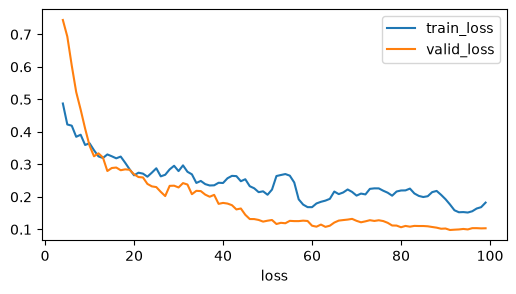

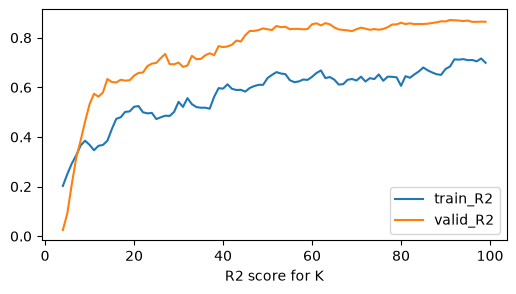

In [ ]:
# training & vaidation
def l1_regularization(model, lambda_l1):
    l1_norm = torch.tensor(0., requires_grad=True)
    for name, param in model.named_parameters():
        if 'conv1' in name:
            l1_norm = l1_norm + torch.sum(torch.abs(param))
    return lambda_l1 * l1_norm

def validation(model, dataloader):
    model.eval()
    loss = 0.
    # valid_loss = 0.

    for batch_idx, (input, target) in enumerate(dataloader):
        input = input.to(device)
        target = target.to(device)  # add negative for ln()

        with torch.no_grad():
            output = model(input)
        
        # compute loss & r2 score
        loss = criterion(output,target)
        r2score = R2Score().to(device)
        r2_lnK = r2score(output.reshape(-1,1), target.reshape(-1,1)).detach()

    return loss,  r2_lnK

valid_loss = 0.
result_list = []
prev_lr = optimizer.param_groups[0]['lr']
print('Start training')
for epoch in range(1,args['n_epochs'] +1):  # args['n_epochs']

    model.train()
    for batch_idx, (input, target) in enumerate(train_dataloader): 

        input = input.to(device)
        target = target.to(device)

        # Clear gradient
        model.zero_grad()

        # forward propagation
        output = model(input)

        # calculate loss
        loss = criterion(output, target)

        l1 = l1_regularization(model, args['l1_weight'])
        loss += l1
        
        # back propagation (gradient calculate)
        loss.backward()

        # parameter update
        optimizer.step()
        if batch_idx % 500 == 0:
            print(f'For epoch:{epoch}/batch:{batch_idx} training loss = {loss.item():.3f}') 
            # print(f'training loss: {loss:.3f}')
        
    # validation
    valid_loss,  r2_lnK_valid  = validation(model, valid_dataloader)

    # scheduler.step()
    scheduler.step() # valid_loss

    # R2 score
    r2score = R2Score().to(device)
    r2_lnK = r2score(output.reshape(-1,1), target.reshape(-1,1)).detach()
    
    current_lr = optimizer.param_groups[0]['lr']
    if current_lr != prev_lr:
        print(f"Epoch {epoch+1}: Learning rate changed to {current_lr:.8f}")
        prev_lr = current_lr
    
    # append & print output
    result_list.append((    current_lr,
                            loss.item(),
                            valid_loss.item(),
                            r2_lnK.cpu().numpy(),
                            r2_lnK_valid.cpu().numpy(),
    ))

    # print('-----------------------------------------------------------------')
    print(f"epoch {epoch}/{args['n_epochs']} | MSE train Loss: {loss:.3f} |train R2 (lnK): {r2_lnK:.3f} | MSE valid Loss: {valid_loss:.3f} | valid R2 (lnK): {r2_lnK_valid:.3f} ")
    
    # saving checkpoint
    if r2_lnK_valid >0.85 or epoch == args['n_epochs']:
        print('-----------------------------------------')
        print(f'saving checkpoint at epoch = {epoch}')
        print('-----------------------------------------')
        
        save_folder = save_folder = ( Path.cwd() / "training_result" / args["saving_name"])
        os.makedirs( save_folder, exist_ok=True)
        
        training_name = args['saving_name'] + '_epoch_' + str(epoch) + '.pth'
        
        checkpoint ={
                    'args': args, 
                    # 'epoch': epoch,
                    'train_loss':  loss,
                    'valid_loss':  valid_loss,
                    # 'batch_size':  args['batch_size'],
                    # 'growth_rate': args['growth_rate'],
                    # 'l1_weight':   args['l1_weight'],            
                    'model_state_dict': model.state_dict(),
                    'optimizer_state_dict': optimizer.state_dict()}

        torch.save(checkpoint, save_folder/training_name)
print('-------------------------')
print('Finish training')

# metrices records
df_metrics = pd.DataFrame(np.array(result_list), columns= [ 'lr', 'train_loss','valid_loss','train_K_R2' ,'valid_K_R2']) # , 'valid_K_R2', 'valid_Ss_R2'])
df_metrics.to_csv(os.path.join(save_folder, args['saving_name'] + '_epoch_' + str(epoch) + '.csv'))

plt.figure(figsize = (6,3))
plt.plot(df_metrics['train_loss'].rolling(window=5).mean() ,label = 'train_loss')  
plt.plot(df_metrics['valid_loss'].rolling(window=5).mean(), label = 'valid_loss') 
plt.xlabel('epoch')
plt.xlabel('loss')
plt.legend()

plt.figure(figsize = (6,3))
plt.plot(df_metrics['train_K_R2'].rolling(window=5).mean() ,label = 'train_R2')  
plt.plot(df_metrics['valid_K_R2'].rolling(window=5).mean(), label = 'valid_R2') 
plt.xlabel('epoch')
plt.xlabel('R2 score for K')
plt.legend()
plt.show()


### Model performance

In [ ]:
# load model checkpoint
ckpt_path = Path.cwd()/'training_result'/args['saving_name']/'test_1114_epoch_100.pth'
checkpoint = torch.load(ckpt_path, map_location='cpu', weights_only=False)

model_predict = HTNN_Net(
            in_channels   = checkpoint['args']['in_channels'],     # Adjust based on your input channels
            init_features = checkpoint['args']['init_features'],
            out_channels  = checkpoint['args']['out_channels'],
            growth_rate   = checkpoint['args']['growth_rate'],
            layer_num     = checkpoint['args']['layer_num'],       # Adjust based on your architecture
            drop_rate     = checkpoint['args']['drop_rate']
        )

model_predict = model_predict.to(device)
model_predict.load_state_dict(checkpoint['model_state_dict'])
model_predict = model_predict.eval()

valid_eval_dataloader = DataLoader( dataset = valid_data, batch_size = 1 )
test_eval_dataloader = DataLoader( dataset = test_data, batch_size = 1)

 R2 score (test): 0.868
 R2 score (test): 0.663
 R2 score (valid): 0.396
 R2 score (valid): 0.793


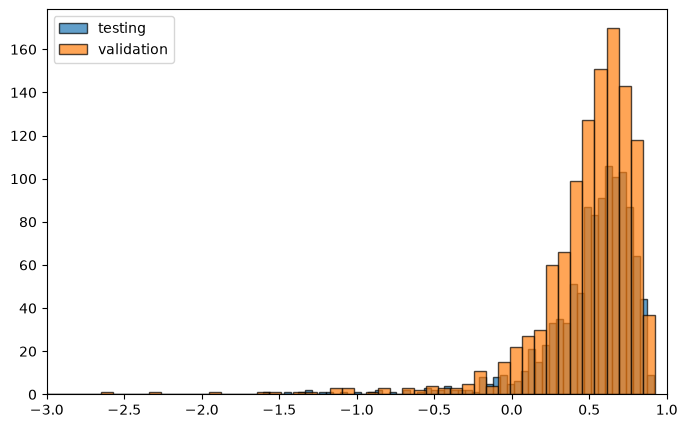

In [325]:
# evaluate validation and testing dataset
test_r2_score = []
valid_r2_score = []

for idx, (x, y) in enumerate(test_eval_dataloader):
    
    y_pre = model_eval(model_predict, x.to(device))
    test_r2_score.append(r2_score(y_pre.reshape(-1), y.reshape(-1)))
    if idx % 1000 ==0:
        print(f" R2 score (test): { r2_score(y_pre.reshape(-1), y.reshape(-1)):.3f}")

for idx, (x, y) in enumerate(valid_eval_dataloader):
    
    y_pre = model_eval(model_predict, x.to(device))
    valid_r2_score.append(r2_score(y_pre.reshape(-1), y.reshape(-1)))
    if idx % 1000 ==0:
        print(f" R2 score (valid): { r2_score(y_pre.reshape(-1), y.reshape(-1)):.3f}")

plt.figure(figsize=(8, 5))
plt.hist(test_r2_score, bins=200, edgecolor='black', alpha=0.7, label= "testing")
plt.hist(valid_r2_score, bins=200, edgecolor='black', alpha=0.7, label= "validation")
plt.xlim(-3, 1)
plt.legend()
plt.show()


### Sythetic case testing

In [ ]:
# create sythetic case
project_name = 'toy_case_2D'
forward_dir = os.path.join(os.getcwd(), 'toy_case')
simulation_control = ('2D', 'transient', 'confined')  # dimension, problem, aquifer

# river signal
df_sigs = pd.read_csv(work_dir/'river_sigs.csv')
sigs = df_sigs['river'].values
init_h = sigs[0]

# Geometry
dx = np.array([30] *50)
dy = np.array([30] *60)
start_coord = (0,  0)           # origin coordinate (x0, y0)
element_num = (50, 60)        # element number in each direction (e_x, e_y)
element_spacing = (dx, dy)      # element spacing in each direction (len(dx) = e_x)
init_paras = (init_h, 0, 1.25, 0.0005, 0.4) # init_h, init_flux, init_K, init_Ss, porosity

# sleio
sy_model = sle_io('sythetic model', forward_dir)
sy_model.set_parameters(simulation_control)
sy_model.create_geometry(start_coord, element_num, element_spacing)
sy_model.create_initial(init_paras)
df_ele_coor = sy_model.df_coordinate.copy()
df_node_coor = sy_model.df_node_coordinate.copy()

# Sythetic field
forward_dir = work_dir / "toy_case"
rf_mean = 1.25
rf_variance = 0.75
seed = 20261115
ln_var = np.log1p(rf_variance / rf_mean**2)
ln_mean = np.log(rf_mean) - 0.5 * ln_var
correlation_scale = [300,300] 
sy_model.random_gaussian_field( correlation_scale, ln_mean, ln_var, seed)

Project: sythetic model
Work on folder:C:\Users\Ethan\Desktop\ethan\專案\HTNN-2D\toy_case
Simulation in '2D' case, 'confined' aquifer under 'transient' state


In [332]:
# run forward simulatoin
sy_model.run_forward(sy_model.grf)
sy_model.read_stress_FwdObs()

# input head matrix
df_head = sy_model.stress_result['stress_1']
df_head['river'] = sigs - sigs[0]
select_time_idx = np.arange(1, 100, 2)
head = df_head.iloc[select_time_idx].values
input_x = head.reshape(1, 1, 50, 25)

# model prediction
y_pre = model_eval(model_predict, input_x)
htnn_pre = y_pre.reshape(-1)

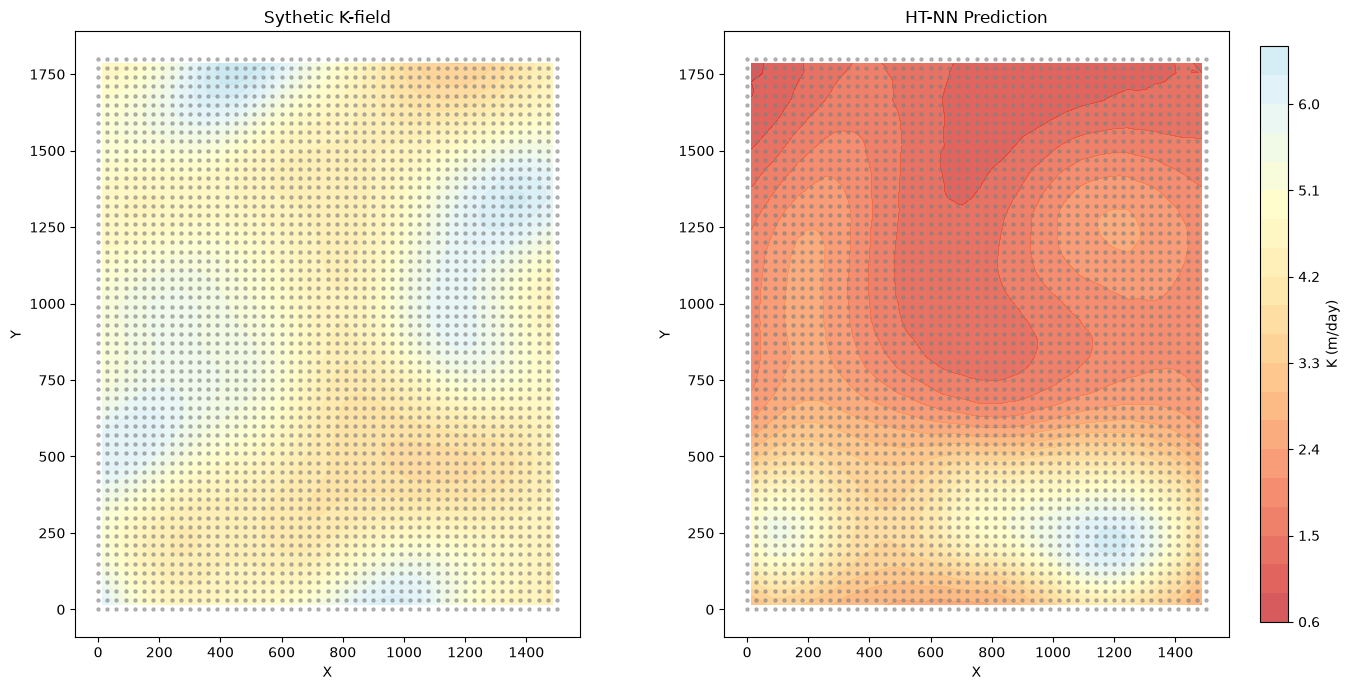

In [ ]:
# plot contour
fig, axes = plt.subplots(1, 2, figsize=(14, 7))

fields = [sy_model.grf, htnn_pre]
titles = ['Sythetic K-field', 'HT-NN Prediction']

for ax, field, title in zip(axes, fields, titles):

    cf = ax.tricontourf( df_ele_coor['x'], df_ele_coor['y'], field, levels=20, cmap='RdYlBu', vmin=0, vmax=10, alpha=0.75)

    ax.scatter( df_node_coor['x'], df_node_coor['y'], s=5, color='gray', alpha=0.5)
    ax.set_aspect('equal', adjustable='box')
    ax.set_xlabel('X')
    ax.set_ylabel('Y')
    ax.set_title(title)

fig.colorbar(cf, shrink=0.95, fraction=0.08, label='K (m/day)')
plt.tight_layout()
plt.show()

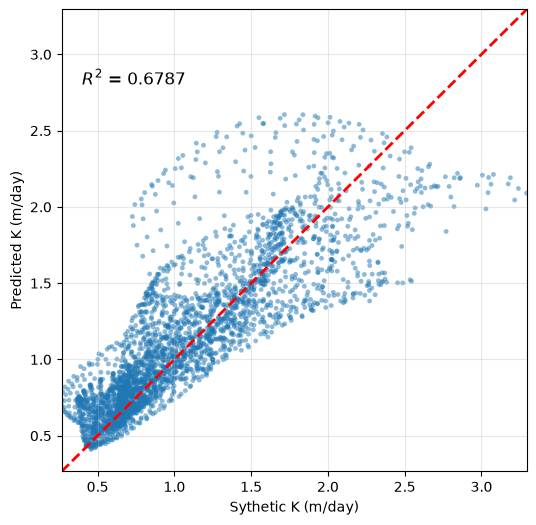

In [ ]:
# scatter plot
true = np.asarray(sy_model.grf).flatten()
pred = np.asarray(htnn_pre).flatten()
r2 = r2_score(true, pred)

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter( true, pred, s=12, alpha=0.5, edgecolors='none')
vmin = min(true.min(), pred.min())
vmax = max(true.max(), pred.max())
ax.plot( [vmin, vmax], [vmin, vmax], 'r--', linewidth=2 )

ax.set_xlim(vmin, vmax)
ax.set_ylim(vmin, vmax)
ax.set_xlabel('Sythetic K (m/day)')
ax.set_ylabel('Predicted K (m/day)')

ax.text(vmin*1.5, vmax*0.9, f'$R^2$ = {r2:.4f}', fontsize=12)
ax.grid(alpha=0.3)
plt.show()